# Titanic Dataset
This noebook goes through the exploratory data analysis of the famous Titanic Dataset available on [Kaggle](https://www.kaggle.com/competitions/titanic). This is the first notebook for this 'lab' assignment.

Task have been generated by ChatGPT, the answers are my own.

## TAKS 01 - Problem Definition & Success Metric

Write a short note (top of notebook) answering

- What is the prediction target?
    - Just a quick look at the columns in the dataset, and we can figure out that the goal is to predict weather a passenger survived based on the given data. Surely enough, the competition page also mentions the same. The `Survived` column is also missing from the `test.csv` file, reinforcing the fact that the our model must predict the survival of the passengers.


- What is the success metric?
    - For this prediction task, the primary evaluation metric will be ROC-AUC, because it measures how well the model distinguishes between survivors and non-survivors across all classification thresholds. Since survival prediction is a binary classification problem with moderate class imbalance, ROC-AUC provides a more robust measure than accuracy.
    - As a secondary metric, I will monitor F1-score, because it balances precision and recall and gives a better sense of overall classification performance than accuracy alone. Accuracy will be reported, but not used as the main success criterion due to its sensitivity to class imbalance.

- What business question does this answer? (E.g., “Which passenger features correlate with survival?”)
    - Studying this dataset and developing an accurate model for predicting survival would help us understand quite a few thing. A couple that immediately come to mind are:
        - Which features affect the survival rate the most?
        - How does each feature affect the survival rate? Is it the feature a positive incluence or a negative one?

## Task 02 - Quick EDA

Do these, and add one-line interpretation for each result.

a. Load data and show `.info()` and `.describe()`.

b. Show counts of target classes. (Is it imbalanced?)

c. Visualize distributions:

- Histogram of `Age`, `Fare`

- Bar plot of `Pclass` vs survival rate

- Sex vs survival rate

d) Check missingness: which columns have missing values and how many?

Hints:

Use `seaborn.countplot` or `pandas.crosstab` for survival rates.

Missing values: `df.isna().sum()`.

In [25]:
import pandas as pd

In [26]:
df = pd.read_csv('../data/train.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Looks like the data is more or less all there. There is some missing data for `Age`, `Cabin`, and `Embarked` caolumns.

In [28]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


All the data here looks reasonable enough. Seems like there are no apparant outliers to be handled.

In [29]:
df.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [30]:
df.Survived.value_counts() / len(df)

Survived
0    0.616162
1    0.383838
Name: count, dtype: float64

Looks like the target classes are not balanced. About 62% passengers have died and only about 38% seem to have survived. So, a naive model that predicts target class `0`  for all passengers will be correct 62% of the times. This is our baseline to beat.

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='Age', ylabel='Count'>

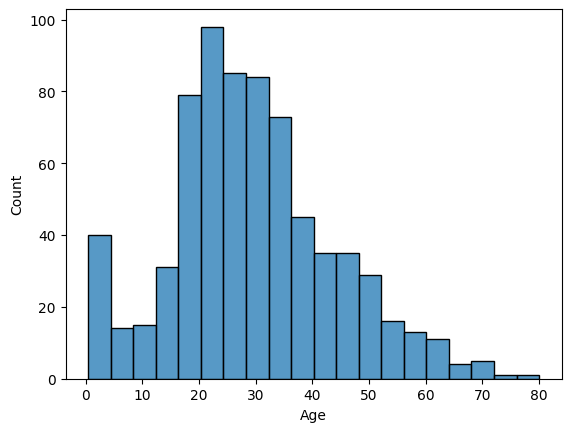

In [32]:
sns.histplot(df, x='Age')

A very normal normal curve, with the exception of disproportionately high amount of children/infants.

<Axes: xlabel='Fare', ylabel='Count'>

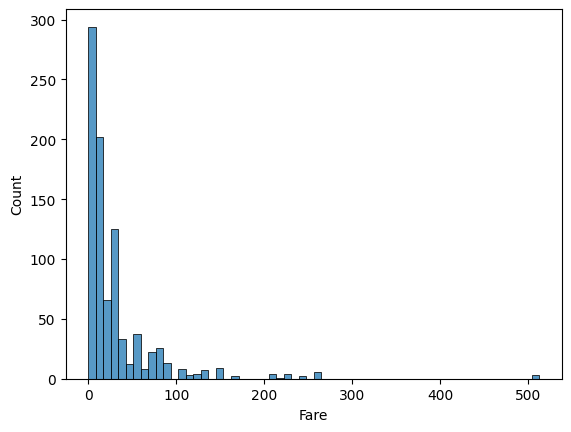

In [33]:
sns.histplot(df, x='Fare')

Looks like a regular exponentially decaying curve. Looks like it should have ended at under `$300`, but an out lying `$500` fare has also been recorded

<Axes: xlabel='Pclass', ylabel='Survived'>

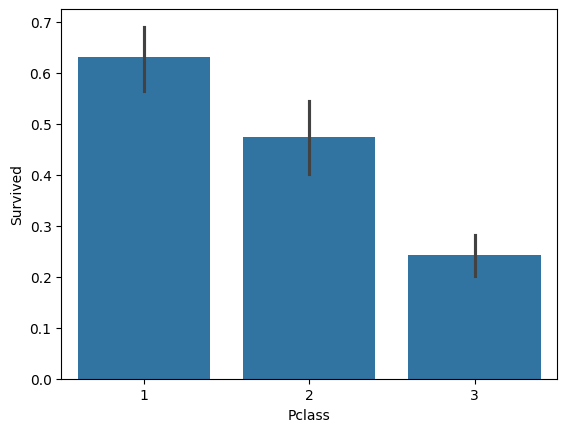

In [34]:
sns.barplot(data=df, x='Pclass', y='Survived')

Looks like higher class passengers had better survival rate, compared to the lower ones. Likely due to the ship management giving preferential treatment to passengers who paid the highest fares aka higher class.

<Axes: xlabel='Sex', ylabel='Survived'>

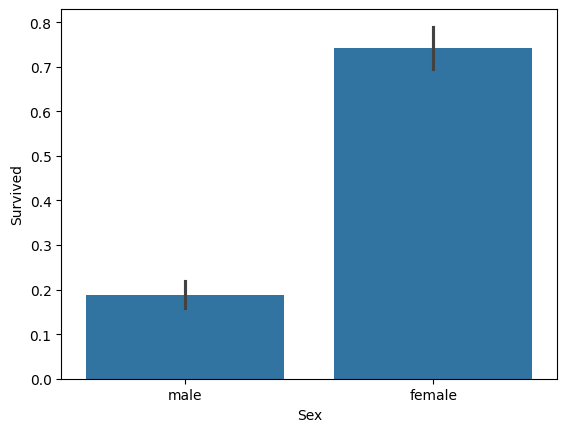

In [35]:
sns.barplot(data=df, x='Sex', y='Survived')

Men seem to have disproportionately low survival rate, likely due to everyone letting women and children (also possibly the elderly) to get on lifeboats before letting the men get on.

In [36]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Quite a few missing values in `Age` and `Cabin` columns. I feel like Cabin number probably doesn't matter as much can probably can be ignored. Age is something I will have to think about how to handle. A couple of missing values in `Embarked` are easy to handle, we'll just assume they embarked in `Queensland` which is in Ireland, which is probably the last stop before sailing into the Atlantic Ocean.

## Task 03 - Simple Feature Engineering

Create a new notebook cell or `data_utils.py` to implement simple, explainable features:

1. `Sex` → binary `is_male` (1 if male else 0).

2. `Title` extracted from `Name` (Mr, Mrs, Miss, Master, Other). Create `title` and then one-hot or map to small groups.

3. `FamilySize` = `SibSp + Parch + 1`. Create `is_alone` (FamilySize==1).

4. Fill missing `Age` with median or with group median (by `Pclass`+`Title`) — try median first.

5. Fill missing `Embarked` with mode.

6. Optionally: log-transform `Fare` if skewed.

Deliverable: a small function `preprocess(df)` that returns features DataFrame `X` and target `y`. Put this in `src/data_utils.py`.

Hint: implement stepwise and test `preprocess(df.head())` to inspect output.

In [37]:
import sys
import os
sys.path.append(os.path.abspath(".."))

In [38]:
import importlib
import src.data_utils
importlib.reload(src.data_utils)

<module 'src.data_utils' from 'e:\\Study\\Programming\\Machine Learning\\Lab-01-Titanic\\src\\data_utils.py'>

In [39]:
import src.data_utils as du

In [40]:
X, y = du.preprocess(df)

In [41]:
X, y

(     Pclass   Age     Fare Embarked  Gender  Title  FamilySize  IsAlone
 0         3  22.0   7.2500        S       1     Mr           2        1
 1         1  38.0  71.2833        C       0    Mrs           2        1
 2         3  26.0   7.9250        S       0   Miss           1        0
 3         1  35.0  53.1000        S       0    Mrs           2        1
 4         3  35.0   8.0500        S       1     Mr           1        0
 ..      ...   ...      ...      ...     ...    ...         ...      ...
 886       2  27.0  13.0000        S       1  Other           1        0
 887       1  19.0  30.0000        S       0   Miss           1        0
 888       3  28.0  23.4500        S       0   Miss           4        1
 889       1  26.0  30.0000        C       1     Mr           1        0
 890       3  32.0   7.7500        Q       1     Mr           1        0
 
 [891 rows x 8 columns],
 0      0
 1      1
 2      1
 3      1
 4      0
       ..
 886    0
 887    1
 888    0
 889   

In [42]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Gender           0
Title            0
FamilySize       0
IsAlone          0
dtype: int64

All the preprocessing objectives have been completed for this task. Likewise, we have also reached the end of our data exploration part. `Task 04` and onwards will be continued in the `02_modelling.ipynb` notebook.